<a href="https://colab.research.google.com/github/kvikaee/data-analysis-python/blob/main/2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Кошурина Виктория Евгеньевна

412977

 # 🎓 Задание: «Работа с изображением как с NumPy-массивом»

> **Цель**: Отработать ключевые операции NumPy — срезы, слои, broadcasting, транслирование — на реальном примере изображения.  
> **Ограничение**: Использовать `matplotlib.pyplot` только для команды `plt.imshow()` — чтобы показать результат.


## 📥1: Загрузите изображение

Используйте любое цветное изображение на свое усмотрение.  
Загрузите его в массив NumPy двуся способами с  `imageio` (рекомендовано) и  `PIL`.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import imageio.v3 as iio
img = iio.imread('3.jpg')

print("Форма изображения:", img.shape)  # проверьте


Форма изображения: (716, 736, 3)


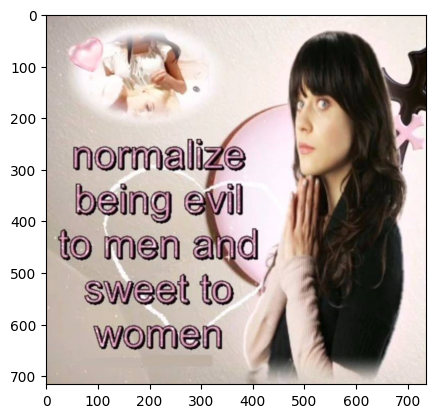

In [ ]:
plt.imshow(img)
plt.show()

## ✂️ 2: Срезы и слои (оси)

### Задание 2.1: Выведите отдельные цветовые каналы

- Создайте три новых массива: только красный канал, только зелёный, только синий.
- Покажите каждый канал как отдельное изображение (остальные каналы = 0).


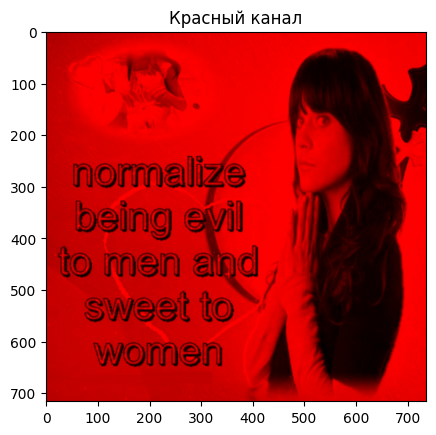

In [ ]:
red_channel = img.copy()
red_channel[:, :, 1] = 0  # обнуляем зелёный
red_channel[:, :, 2] = 0  # обнуляем синий
plt.imshow(red_channel)
plt.title("Красный канал")
plt.show()

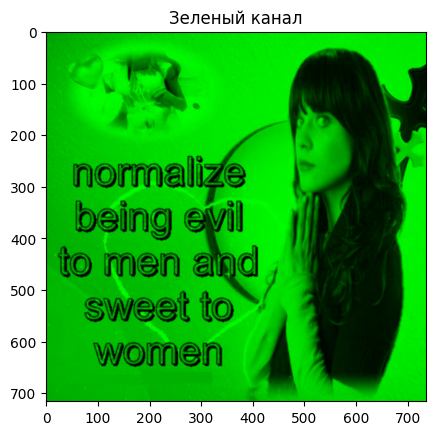

In [ ]:
green_channel = img.copy()
green_channel[:, :, 0] = 0  # обнуляем красный
green_channel[:, :, 2] = 0  # обнуляем синий
plt.imshow(green_channel)
plt.title("Зеленый канал")
plt.show()

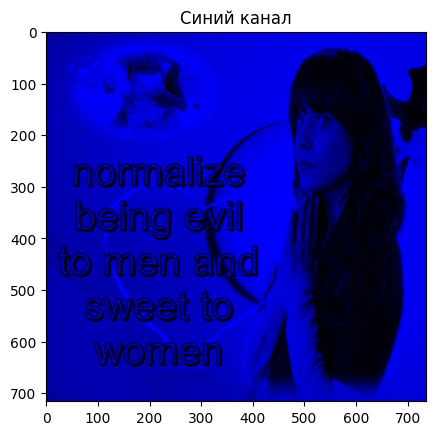

In [ ]:
blue_channel = img.copy()
blue_channel[:, :, 0] = 0  # обнуляем красный
blue_channel[:, :, 1] = 0  # обнуляем зеленый
plt.imshow(blue_channel)
plt.title("Синий канал")
plt.show()

# 🖼️  3: Работа с чёрно-белым изображением

### Задание 3.1: Преобразуйте цветное изображение в чёрно-белое

Используйте формулу среднего весового:
  ```python
  gray = 0.299 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.114 * img[:, :, 2]
  ```





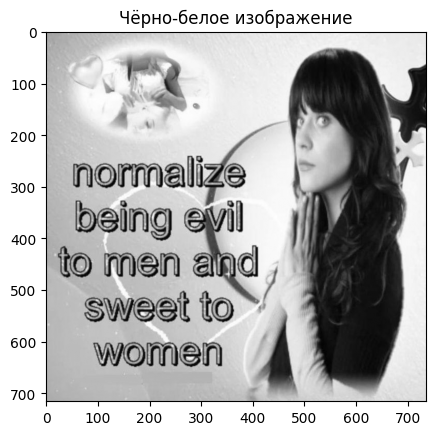

In [ ]:
gray = 0.299 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.114 * img[:, :, 2]
gray = gray.astype(np.uint8)
plt.imshow(gray, cmap='gray')
plt.title("Чёрно-белое изображение")
plt.show()

> 💡 Это соответствует стандартному алгоритму преобразования RGB → grayscale.


## 🧮  4: Сжатие (уменьшение разрешения)

### Задание 4.1: Уменьшите изображение в 2 раза по каждой оси

- Используйте срезы с шагом: `img[::2, ::2]`
- Это простейший способ "даунсэмплинга".


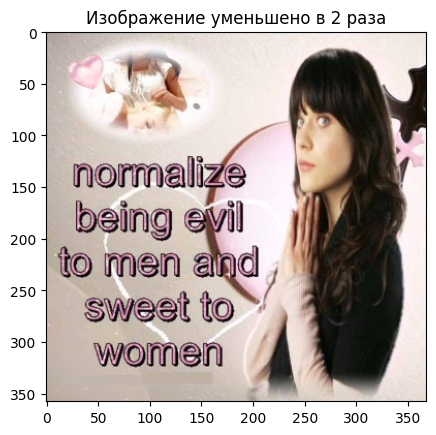

In [ ]:
small_img = img[::2, ::2]
plt.imshow(small_img)
plt.title("Изображение уменьшено в 2 раза")
plt.show()

## 🚫 5: Затирание (зануление) поля на изображении

### Задание 5.1: Затрите прямоугольную область на изображении

- Выберите координаты прямоугольника .
- Присвойте всем пикселям в этом участке значение `[0, 0, 0]` (чёрный).

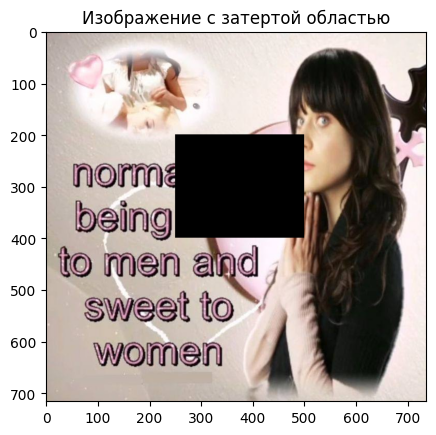

In [ ]:
img_erased = img.copy()

x_start, x_end = 200, 400
y_start, y_end = 250, 500

img_erased[x_start:x_end, y_start:y_end] = [0, 0, 0]

plt.imshow(img_erased)
plt.title("Изображение с затертой областью")
plt.show()

## 🔁 6: Перевороты изображения

### Задание 6.1: Горизонтальный переворот

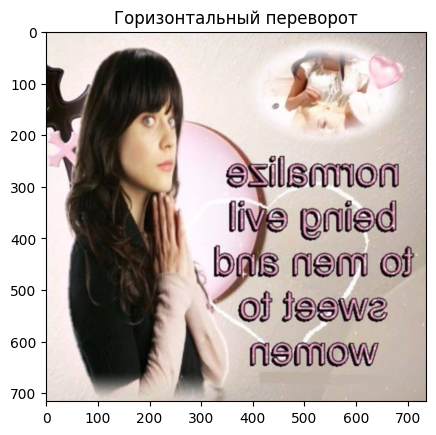

In [ ]:
flipped_horizontal = np.flip(img, axis=1)  # и img[:, ::-1]
plt.imshow(flipped_horizontal)
plt.title("Горизонтальный переворот")
plt.show()

### Задание 6.2: Вертикальный переворот

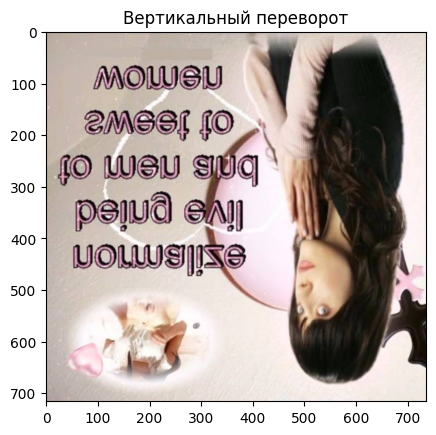

In [ ]:
flipped_vertical = np.flip(img, axis=0)  # и img[::-1, :]
plt.imshow(flipped_vertical)
plt.title("Вертикальный переворот")
plt.show()

### Задание 6.3: Полный поворот на 180°

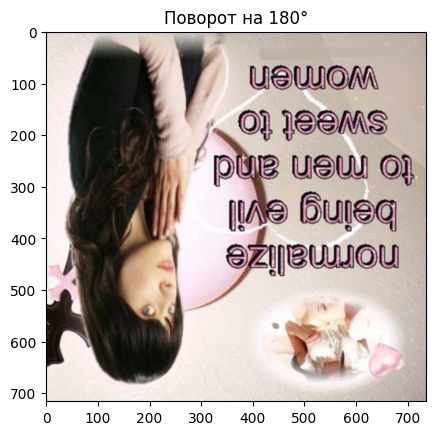

In [ ]:
rotated_180 = np.flip(img, axis=(0, 1))
plt.imshow(rotated_180)
plt.title("Поворот на 180°")
plt.show()

## 🔄 7: Broadcasting — наложение маски / фильтра

### Задание 7.1: Сделайте изображение “теплее” — увеличьте красный канал на 50

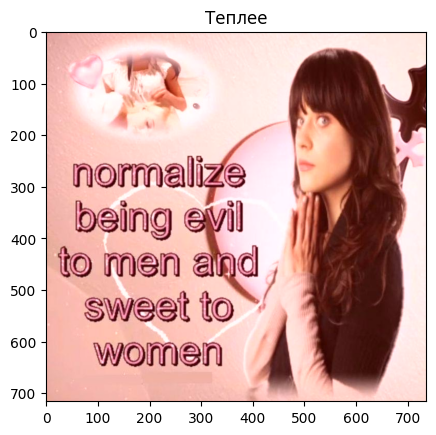

In [ ]:
filter = np.array([50, 0, 0])

img_warmer = img.astype(np.int16) + filter      # считаем в более широком типе
img_warmer = np.clip(img_warmer, 0, 255)       # обрезаем в допустимый диапазон
img_warmer = img_warmer.astype(np.uint8)       # возвращаем uint8

plt.imshow(img_warmer)
plt.title("Теплее")
plt.show()


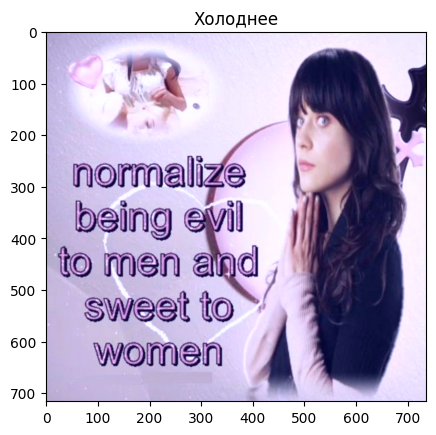

In [ ]:
filter1 = np.array([0, 0, 50])

img_colder = img.astype(np.int16) + filter1      # считаем в более широком типе
img_colder = np.clip(img_colder, 0, 255)       # обрезаем в допустимый диапазон
img_colder = img_colder.astype(np.uint8)       # возвращаем uint8

plt.imshow(img_colder)
plt.title("Холоднее")
plt.show()


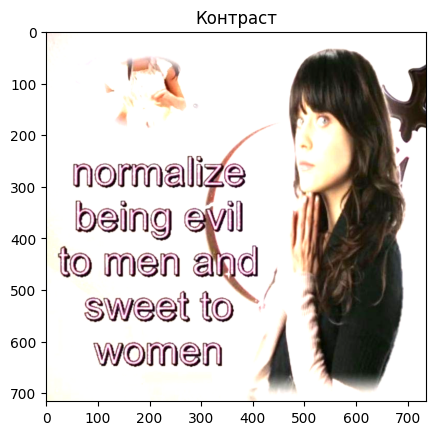

In [ ]:
filter2 = np.array([1.5, 1.5, 1.5])

img_contrast = img.astype(np.int16) * filter2      # считаем в более широком типе
img_contrast = np.clip(img_contrast, 0, 255)       # обрезаем в допустимый диапазон
img_contrast = img_contrast.astype(np.uint8)       # возвращаем uint8

plt.imshow(img_contrast)
plt.title("Контраст")
plt.show()


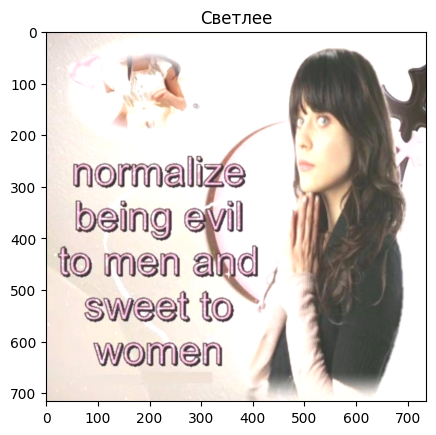

In [ ]:
filter3 = np.array([50, 50, 50])

img_bright = img.astype(np.int16) + filter3
img_bright = np.clip(img_bright, 0, 255).astype(np.uint8)

plt.imshow(img_bright)
plt.title("Светлее")
plt.show()


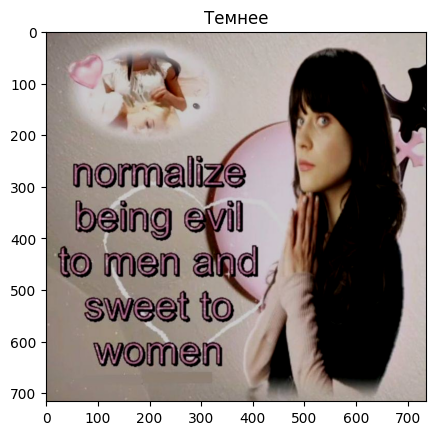

In [ ]:
filter4 = np.array([-50, -50, -50])

img_dark = img.astype(np.int16) + filter4
img_dark = np.clip(img_dark, 0, 255).astype(np.uint8)

plt.imshow(img_dark)
plt.title("Темнее")
plt.show()

## 🎭  8: Транслирование — объединение с другим изображением

### Задание 8.1: Создайте градиентную маску и наложите её

- Создайте массив формы `(H, W, 1)` — например, линейный градиент по высоте.
- Смешайте исходное изображение с инвертированным, используя градиент как вес.

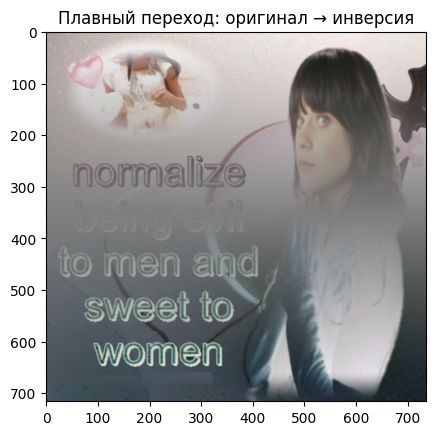

In [ ]:
H, W = img.shape[:2]
gradient = np.linspace(0, 1, H)[:, None, None]  # (H, 1, 1)

inverted = 255 - img
blended = (img * (1 - gradient) + inverted * gradient).astype(np.uint8)
plt.imshow(blended)
plt.title("Плавный переход: оригинал → инверсия")
plt.show()

# 🎓 Задание: «Реализация kNN — сравнение чистого Python и NumPy»

> **Цель**: Проанализировать разницу между поэлементными циклами и векторизованными операциями.  
> **Задача**: Реализовать алгоритм k ближайших соседей двумя способами — без библиотек и с NumPy — и сравнить время выполнения.

In [ ]:
import numpy as np
import time

# Обучающая выборка: 1000 точек в 3D-пространстве
np.random.seed(42)
X_train = np.random.rand(1000, 3) * 100  # координаты от 0 до 100
y_train = np.random.choice(['A', 'B', 'C'], size=1000)  # метки классов

# Точка, которую нужно классифицировать
X_test = np.array([50.0, 50.0, 50.0])
k = 5  # Количество соседей, попробуйте разные значения, сравните результаты

## ⚙️ Шаг 2: Реализация на чистом Python (без NumPy)

In [ ]:
import math
from collections import Counter

def knn_pure_python(X_train, y_train, X_test, k):
    # 1. превращаем numpy-массивы в обычные списки Python
    X_train_list = X_train.tolist()
    y_train_list = y_train.tolist()
    X_test_list = X_test.tolist()

    distances = []

    # 2. проходимся циклом по всем точкам и считаем расстояние
    for i in range(len(X_train_list)):
        point = X_train_list[i]
        label = y_train_list[i]

        # евклидово расстояние: sqrt((x2-x1)^2 + (y2-y1)^2 + (z2-z1)^2)
        # считаем вручную для каждого из 3 измерений
        dist = math.sqrt(
            (point[0] - X_test_list[0])**2 +
            (point[1] - X_test_list[1])**2 +
            (point[2] - X_test_list[2])**2
        )

        # сохраняем пару (расстояние, класс)
        distances.append((dist, label))

    # 3. сортируем по расстоянию (от меньшего к большему)
    distances.sort(key=lambda x: x[0])

    # 4. берем топ-k соседей
    k_nearest = distances[:k]

    # 5. голосование: считаем, какой класс встречается чаще всего
    # собираем только метки классов от ближайших соседей
    k_nearest_labels = [label for dist, label in k_nearest]

    # находим самый частый элемент
    most_common = Counter(k_nearest_labels).most_common(1)[0][0]

    return most_common


# засекаем время
start_time = time.time()
result = knn_pure_python(X_train, y_train, X_test, k)
end_time = time.time()

print(f"Предсказанный класс: {result}")
print(f"Время выполнения (Pure Python): {end_time - start_time:.6f} сек")


Предсказанный класс: B
Время выполнения (Pure Python): 0.001478 сек


.tolist(): Превращает быстрые NumPy-массивы в медленные списки Python (как требовалось в задании).

Цикл for: Мы перебираем каждую из 1000 точек по одной, что очень медленно.

math.sqrt(...): Считаем геометрию вручную.

Counter: Удобная штука, чтобы посчитать голоса (например, если соседи ['A', 'A', 'B'], он скажет, что победил 'A').

In [ ]:
def knn_numpy(X_train, y_train, X_test, k):
    # 1. вычисляем расстояния (Векторизация!)
    # X_train - X_test: NumPy вычитает X_test из каждой строки X_train
    # axis=1 означает, что мы суммируем квадраты координат для каждой точки отдельно
    distances = np.linalg.norm(X_train - X_test, axis=1)

    # 2. сортировка
    # нам нужны не сами расстояния, а индексы точек, отсортированные по возрастанию
    sorted_indices = np.argsort(distances)

    # 3. берем индексы k ближайших
    nearest_indices = sorted_indices[:k]

    # 4. получаем метки классов этих соседей
    nearest_labels = y_train[nearest_indices]

    # 5. голосование
    # np.unique возвращает уникальные классы и то, сколько раз они встретились
    classes, counts = np.unique(nearest_labels, return_counts=True)

    # находим индекс максимального количества голосов
    winner_index = np.argmax(counts)

    return classes[winner_index]

# проверка
start_time = time.time()
result_np = knn_numpy(X_train, y_train, X_test, k)
end_time = time.time()

print(f"Предсказанный класс: {result_np}")
print(f"Время выполнения (NumPy): {end_time - start_time:.6f} сек")


Предсказанный класс: B
Время выполнения (NumPy): 0.017552 сек


np.linalg.norm(..., axis=1): Считает длину вектора сразу для всех 1000 строк.

np.argsort: Вместо полной сортировки значений он возвращает индексы ([10, 5, 99...]), по которым потом можно достать нужные классы из y_train.

In [ ]:
k_values = [1, 3, 10, 50, 100, 500]

print(f"Тестовая точка: {X_test}")
print("-" * 30)

for k in k_values:
    prediction = knn_numpy(X_train, y_train, X_test, k)
    print(f"При k = {k:<3} -> Класс: {prediction}")


Тестовая точка: [50. 50. 50.]
------------------------------
При k = 1   -> Класс: C
При k = 3   -> Класс: A
При k = 10  -> Класс: A
При k = 50  -> Класс: B
При k = 100 -> Класс: B
При k = 500 -> Класс: A


1) Маленькое k (например, k=1):

Чувствительность к шуму: Максимальная.

Если случайно самой близкой точкой окажется "выброс" (шум, ошибка данных) другого класса, алгоритм ошибется. Границы классов получаются очень рваными и сложными.

Результат: Может быть нестабильным.

2) Среднее k (например, k=5 или k=10):

Баланс: Алгоритм смотрит на группу соседей, поэтому одиночные выбросы игнорируются (они перекрываются большинством).

Это обычно дает самый надежный результат.

3) Большое k (например, k=1000):

Сглаживание: Если взять слишком много соседей, мы начинаем захватывать точки, которые находятся очень далеко от нашей цели.

В пределе, если k равно размеру всей выборки, алгоритм просто вернет самый популярный класс во всем наборе данных, игнорируя координаты нашей точки.

Результат: Теряется локальная структура данных.

### Вывод
Алгоритм чувствителен к параметру k.

При слишком малых k (недообучение) модель реагирует на каждую случайную точку-шум.

При слишком больших k (переобучение наоборот, упрощение) модель игнорирует локальные особенности и стремится выдавать просто самый массовый класс.

In [ ]:
import time

# размеры выборок для теста
sizes = [1000, 10000, 100000]
k = 5
X_test_sample = np.array([50.0, 50.0, 50.0])

print(f"{'Размер':<10} | {'Pure Python (сек)':<18} | {'NumPy (сек)':<15} | {'Ускорение (раз)':<15}")
print("-" * 65)

for size in sizes:
    # 1. генерируем данные под текущий размер
    np.random.seed(42)
    X_curr = np.random.rand(size, 3) * 100
    y_curr = np.random.choice(['A', 'B', 'C'], size=size)

    # 2. замеряем pure python (только для малых размеров, иначе зависнет)
    if size <= 10000:  # Для 100к Python будет считать слишком долго
        start = time.time()
        _ = knn_pure_python(X_curr, y_curr, X_test_sample, k)
        py_time = time.time() - start
    else:
        py_time = None  # пропускаем, чтобы не ждать вечность

    # 3. замеряем numpy
    start = time.time()
    _ = knn_numpy(X_curr, y_curr, X_test_sample, k)
    np_time = time.time() - start

    # 4. выводим результат
    if py_time:
        boost = py_time / np_time
        print(f"{size:<10} | {py_time:.5f}            | {np_time:.5f}         | {boost:.1f}x")
    else:
        print(f"{size:<10} | {'(слишком долго)':<18} | {np_time:.5f}         | -")



Размер     | Pure Python (сек)  | NumPy (сек)     | Ускорение (раз)
-----------------------------------------------------------------
1000       | 0.00122            | 0.00083         | 1.5x
10000      | 0.01114            | 0.00096         | 11.5x
100000     | (слишком долго)    | 0.00628         | -


### Вывод
1) На малых объемах (1 000 точек):

Разница невелика (всего 1.5x).

Почему? Накладные расходы на запуск функций NumPy сопоставимы со временем работы самого цикла Python. Здесь выгода не так очевидна.

2) На средних объемах (10 000 точек):

Разрыв резко увеличивается (11.5x).

Pure Python начинает «буксовать», так как время растет линейно (было 0.001 → стало 0.011, выросло в 10 раз).

NumPy почти не заметил увеличения (время почти не изменилось: 0.00083 → 0.00096). Это потому, что современные процессоры умеют обрабатывать данные пачками (SIMD-инструкции), и для них 10к чисел — это всё ещё мало.

3) На больших объемах (100 000 точек):

Разрыв становится критическим.

Мы видим, что для Pure Python мы даже не стали ждать результат (это заняло бы слишком много времени).

NumPy справился за 0.006 сек.

##Итог
Алгоритмическая сложность у обоих методов одинаковая (они делают одну и ту же работу), но константа времени выполнения у NumPy в сотни раз меньше благодаря реализации на C и оптимизации работы с памятью. Чем больше данных, тем важнее использовать NumPy, а не циклы.